# 03 · The selected configuration

A closer look at the configuration selected in notebook 02: the distribution of each interpretation variable by
cluster, which pairs of clusters differ on what, a representative patient for each cluster, and how CDR is
distributed over the clusters. C1 is shown alongside for comparison.

The selected configuration is read from `results/02_compare_configurations/selection.json`.

In [1]:
import json

%run -i ../src/setup.ipynb

from sklearn.metrics import adjusted_rand_score

CMP = cfg.RESULTS_DIR / "02_compare_configurations"
OUT = cfg.RESULTS_DIR / "03_profile_selected"
OUT.mkdir(parents=True, exist_ok=True)

selection = json.loads((CMP / "selection.json").read_text())
SEL, K = selection["selected"], selection["k"]
df = load_analysis_data()

saved = pd.read_csv(CMP / "labels.csv")
assert (saved["patient_id"] == df["patient_id"]).all()
fit = fit_configuration(SEL, K, df)
labels = relabel_by(df, fit["labels"], "MMSE")
assert (labels == saved[SEL].to_numpy()).all(), "refit differs from notebook 02"
c1_labels = saved["C1"].to_numpy()
print(f"Selected configuration: {SEL}, k = {K}, PSI = {selection['aggregate_psi'][SEL]:.3f}")

Selected configuration: C1-b, k = 4, PSI = 0.497


## 1. Profile table

Median [interquartile range] for continuous variables and the share of each category for the others. Clusters are numbered by decreasing mean MMSE.

In [2]:
def iqr_cell(s, digits):
    q1, q2, q3 = s.quantile([0.25, 0.5, 0.75])
    return f"{q2:.{digits}f} [{q1:.{digits}f}, {q3:.{digits}f}]"

def profile_table(labels):
    rows = {}
    for c in np.sort(np.unique(labels)):
        g = df[labels == c]
        cdr = g["CDR"].value_counts(normalize=True).reindex([0, 0.5, 1, 2], fill_value=0) * 100
        rows[f"Cluster {c}"] = {
            "n (%)": f"{len(g)} ({100 * len(g) / len(df):.0f}%)",
            "Age": iqr_cell(g["Age"], 0),
            "MMSE": iqr_cell(g["MMSE"], 0),
            "nWBV": iqr_cell(g["nWBV"], 3),
            "eTIV (cm³)": iqr_cell(g["eTIV"], 0),
            "Education (1-5)": iqr_cell(g["Educ"], 0),
            "SES (1-5)": iqr_cell(g["SES"], 0),
            "CDR 0 / 0.5 / 1 / 2 (%)": " / ".join(f"{v:.0f}" for v in cdr),
            "Men (%)": f"{100 * g['sex'].mean():.0f}",
        }
    return pd.DataFrame(rows)

table = profile_table(labels)
table.to_csv(OUT / f"profile_table_{SEL}.csv")
table

,Cluster 1,Cluster 2,Cluster 3,Cluster 4
n (%),62 (29%),81 (38%),38 (18%),35 (16%)
Age,"58 [51, 64]","78 [73, 84]","78 [73, 81]","78 [72, 83]"
MMSE,"30 [29, 30]","29 [27, 30]","28 [27, 30]","21 [20, 22]"
nWBV,"0.810 [0.789, 0.823]","0.745 [0.723, 0.765]","0.720 [0.696, 0.744]","0.699 [0.675, 0.728]"
eTIV (cm³),"1398 [1334, 1490]","1390 [1322, 1465]","1682 [1602, 1767]","1461 [1363, 1497]"
Education (1-5),"4 [3, 5]","3 [2, 4]","4 [3, 5]","2 [1, 3]"
SES (1-5),"2 [2, 3]","2 [2, 3]","2 [1, 3]","4 [2, 4]"
CDR 0 / 0.5 / 1 / 2 (%),94 / 6 / 0 / 0,69 / 26 / 5 / 0,47 / 50 / 3 / 0,3 / 37 / 54 / 6
Men (%),32,7,84,37


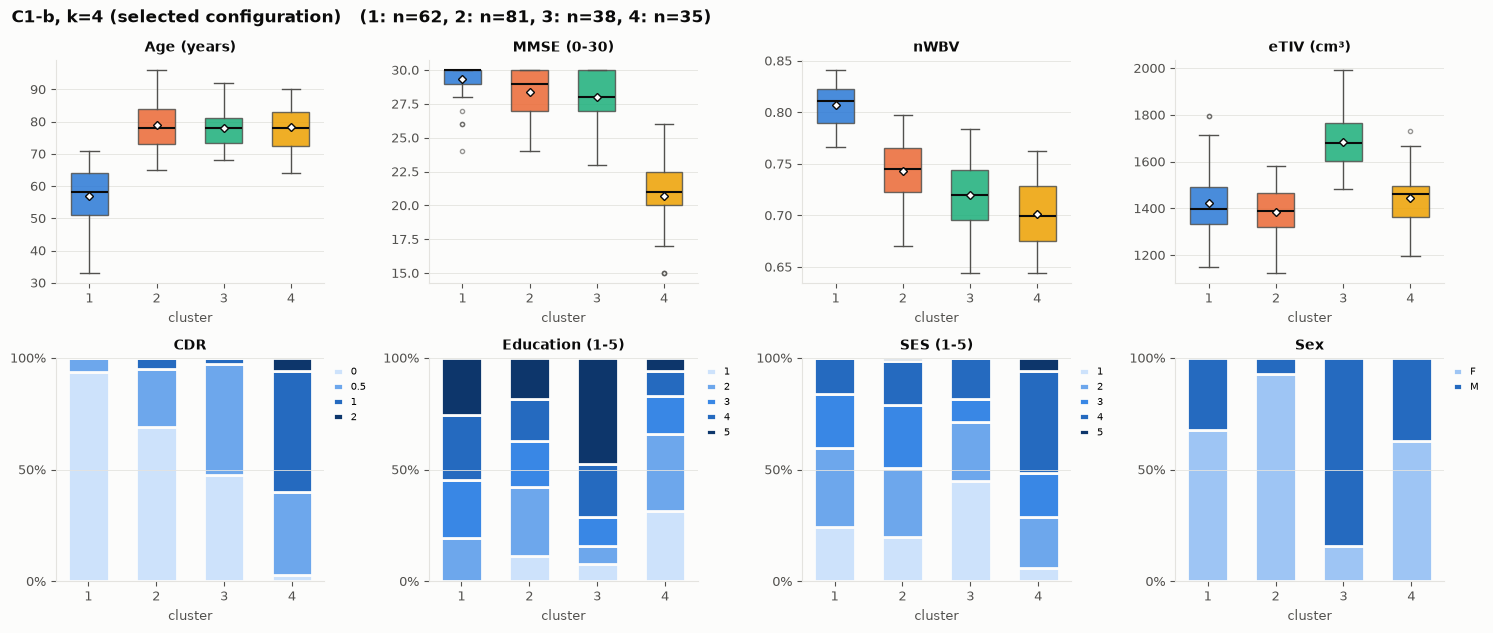

In [3]:
fig = cluster_profile(df, labels, f"{SEL}, k={K} (selected configuration)")
fig.savefig(OUT / f"profile_{SEL}.png", dpi=200, bbox_inches="tight")
plt.show()

## 2. Which pairs of clusters differ on what

Each cell is |Cliff's δ| (TVD for Education, SES and sex) between two clusters on one variable.

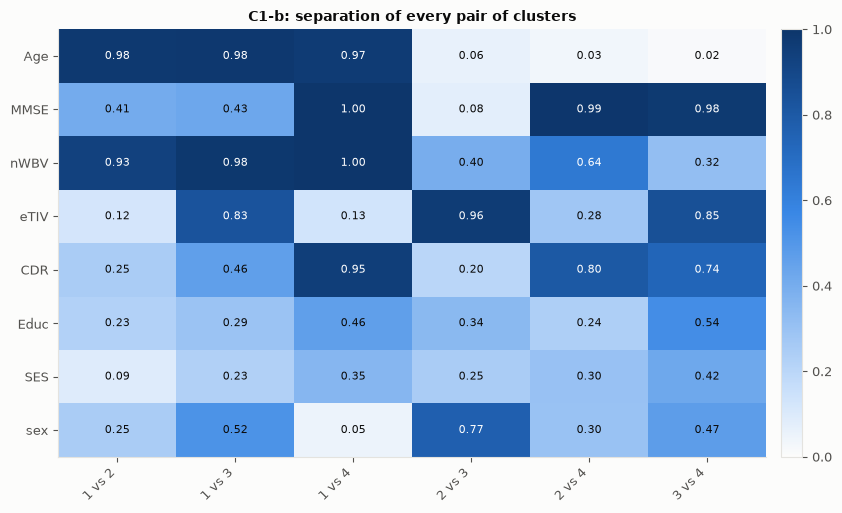

Pairwise Separability report — C1-b
----------------------------------------------------------------------------
Variable Type      Metric        MeanEff Effect      Secondary         Value
----------------------------------------------------------------------------
nWBV   ordinal   cliffs_delta    0.712 large       median_diff       0.060
MMSE   ordinal   cliffs_delta    0.646 large       median_diff       4.667
CDR    ordinal   cliffs_delta    0.566 large       median_diff       0.583
eTIV   ordinal   cliffs_delta    0.530 large       median_diff     156.167
Age    ordinal   cliffs_delta    0.507 large       median_diff      10.000
sex    nominal   TVD             0.392 medium      mode_mismatch     0.500
Educ   nominal   TVD             0.350 medium      mode_mismatch     0.833
SES    nominal   TVD             0.275 small       mode_mismatch     0.833
----------------------------------------------------------------------------
PAIRWISE SEPARABILITY INDEX (mean)    0.497 large      


In [4]:
report = psi_report(df, labels, SEL)
pairs = pd.DataFrame({v.variable: v.to_frame().set_index("pair")["abs_cliffs_delta" if v.var_kind == "ordinal" else "tvd"]
                      for v in report.per_variable}).T
pairs.columns = [p.replace("(", "").replace(")", "").replace(",", " vs ") for p in pairs.columns]
pairs.to_csv(OUT / f"pairwise_{SEL}.csv")
fig = psi_heatmap(pairs, f"{SEL}: separation of every pair of clusters")
fig.savefig(OUT / f"pairwise_{SEL}.png", dpi=200, bbox_inches="tight")
plt.show()
print(report.summary())

## 3. Representative patients

k-means centroids are averages rather than real patients, so each cluster is represented by the patient closest
to its centroid, together with the next two closest patients.

In [5]:
def representatives(fit, labels, n_neighbours=3):
    X = fit["X"]
    rows = []
    for c in np.sort(np.unique(labels)):
        idx = np.where(labels == c)[0]
        if fit["medoids"] is not None:
            centre = X[[m for m in fit["medoids"] if labels[m] == c][0]]
        else:
            centre = X[idx].mean(axis=0)
        order = idx[np.argsort(np.linalg.norm(X[idx] - centre, axis=1))][:n_neighbours]
        for rank, i in enumerate(order):
            rows.append({"cluster": c, "role": "representative" if rank == 0 else f"neighbour {rank}",
                         "patient": df.loc[i, "patient_id"], "sex": df.loc[i, "M/F"],
                         **{v: df.loc[i, v] for v in ["Age", "MMSE", "CDR", "nWBV", "eTIV", "Educ", "SES"]}})
    return pd.DataFrame(rows)

reps = representatives(fit, labels)
reps.to_csv(OUT / f"representatives_{SEL}.csv", index=False)
reps

,cluster,role,patient,sex,Age,MMSE,CDR,nWBV,eTIV,Educ,SES
0,1,representative,OAS1_0378,F,58,30.0,0.0,0.821,1418,2.0,2.0
1,1,neighbour 1,OAS1_0357,F,55,30.0,0.0,0.820,1450,4.0,3.0
2,1,neighbour 2,OAS1_0345,F,54,30.0,0.0,0.831,1389,4.0,2.0
3,2,representative,OAS1_0001,F,74,29.0,0.0,0.743,1344,2.0,3.0
4,2,neighbour 1,OAS1_0244,F,80,29.0,0.0,0.737,1341,4.0,2.0
5,2,neighbour 2,OAS1_0161,F,84,27.0,0.5,0.727,1390,2.0,2.0
6,3,representative,OAS1_0441,M,81,29.0,0.5,0.721,1647,5.0,1.0
7,3,neighbour 1,OAS1_0186,M,84,29.0,0.0,0.731,1707,5.0,1.0
8,3,neighbour 2,OAS1_0418,M,74,28.0,0.5,0.747,1659,5.0,2.0
9,4,representative,OAS1_0233,F,77,20.0,0.5,0.701,1376,1.0,4.0


## 4. CDR by cluster

How the clinical severity scale is distributed over the clusters.

In [6]:
counts = pd.crosstab(pd.Series(labels, name="cluster"), df["CDR"].rename("CDR"), margins=True, margins_name="total")
pct = pd.crosstab(pd.Series(labels, name="cluster"), df["CDR"].rename("CDR"), normalize="index").mul(100).round(0)
counts.to_csv(OUT / f"cdr_composition_{SEL}.csv")
print("Counts:")
display(counts)
print("Row percentages:")
pct

Counts:


CDR,0.0,0.5,1.0,2.0,total
cluster,,,,,
1,58,4,0,0,62
2,56,21,4,0,81
3,18,19,1,0,38
4,1,13,19,2,35
total,133,57,24,2,216


Row percentages:


CDR,0.0,0.5,1.0,2.0
cluster,,,,
1,94.0,6.0,0.0,0.0
2,69.0,26.0,5.0,0.0
3,47.0,50.0,3.0,0.0
4,3.0,37.0,54.0,6.0


## 5. Comparison with C1

ARI = 1 means identical partitions, 0 means no more agreement than chance.

ARI between C1-b and C1: 0.201


C1 cluster,1,2,3,4
C1-b cluster,,,,
1,25,17,18,2
2,16,10,46,9
3,0,34,2,2
4,0,3,10,22


,Cluster 1,Cluster 2,Cluster 3,Cluster 4
n (%),41 (19%),64 (30%),76 (35%),35 (16%)
Age,"68 [55, 73]","74 [63, 81]","75 [68, 83]","78 [72, 82]"
MMSE,"29 [28, 30]","29 [28, 30]","29 [27, 30]","23 [20, 27]"
nWBV,"0.789 [0.760, 0.820]","0.734 [0.706, 0.781]","0.754 [0.732, 0.786]","0.705 [0.681, 0.754]"
eTIV (cm³),"1372 [1313, 1444]","1605 [1505, 1713]","1391 [1327, 1475]","1419 [1322, 1494]"
Education (1-5),"4 [3, 4]","5 [4, 5]","2 [2, 3]","1 [1, 3]"
SES (1-5),"3 [1, 3]","1 [1, 2]","2 [2, 3]","4 [4, 4]"
CDR 0 / 0.5 / 1 / 2 (%),80 / 17 / 2 / 0,64 / 30 / 6 / 0,68 / 22 / 9 / 0,20 / 40 / 34 / 6
Men (%),12,75,14,20


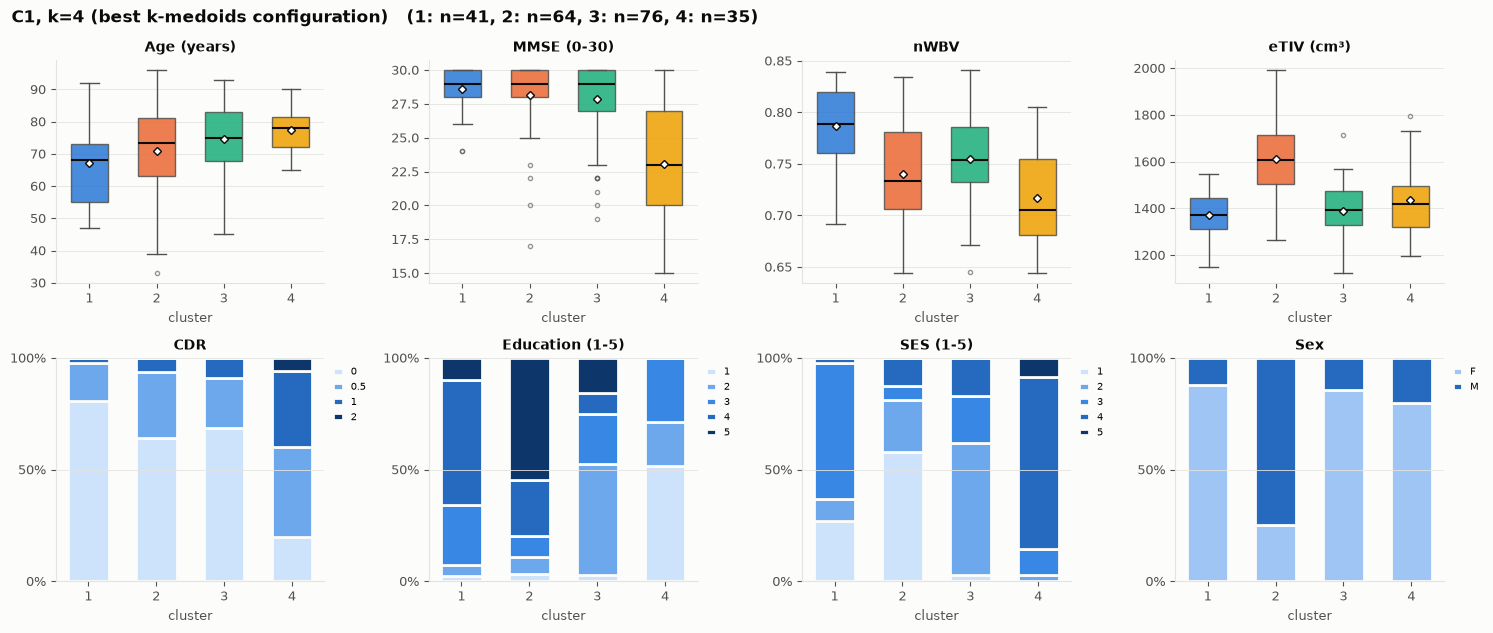

In [7]:
print(f"ARI between {SEL} and C1: {adjusted_rand_score(labels, c1_labels):.3f}")
display(pd.crosstab(pd.Series(labels, name=f"{SEL} cluster"), pd.Series(c1_labels, name="C1 cluster")))
display(profile_table(c1_labels))
fig = cluster_profile(df, c1_labels, f"C1, k={K} (best k-medoids configuration)")
fig.savefig(OUT / "profile_C1.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Interpretation

| | Cluster 1 | Cluster 2 | Cluster 3 | Cluster 4 |
|---|---|---|---|---|
| Label | younger, cognitively healthy | older, healthy, mostly women | older men with large heads, very mild impairment | cognitively impaired |
| Size | 62 (29%) | 81 (38%) | 38 (18%) | 35 (16%) |
| Age | 58 | 78 | 78 | 78 |
| MMSE | 30 | 29 | 28 | 21 |
| nWBV | 0.810 | 0.745 | 0.720 | 0.699 |
| eTIV (cm³) | 1398 | 1390 | 1682 | 1461 |
| CDR > 0 | 6% | 31% | 53% (mostly 0.5) | 97% (60% CDR ≥ 1) |
| Men | 32% | 7% | 84% | 37% |
| Education / SES (median) | 4 / 2 | 3 / 2 | 4 / 2 | 2 / 4 |

- Age and brain volume separate the younger group from all the others (|δ| ≥ 0.97 for Age, ≥ 0.93 for nWBV).
- MMSE and CDR separate the impaired group from the rest (MMSE |δ| between 0.98 and 1.00, CDR between 0.74 and
  0.95). This group also has the lowest education and socioeconomic status.
- Clusters 2 and 3 have the same age and almost the same MMSE; they differ in sex (TVD 0.77) and head size
  (eTIV |δ| = 0.96): cluster 3 is mostly men with large heads, about half of them with CDR 0.5.

Two remarks. Sex now shapes one of the clusters (cluster 3), because it is part of the multiclass block. And C1 and
C1-b agree only partly (ARI = 0.20). In C1 (G-Gower) the multiclass block weighs as much as the four quantitative
variables together (50% of the distance), while in C1-b the one-hot columns of Education, SES and sex make up about
a third of the k-means variance. C1 therefore follows education, SES and sex more, and C1-b age, brain volume and
cognition more.